# MUnL — exact machine unlearning with SISA

Walkthrough of the `munl` package on the FNMA loan dataset: train a SISA ensemble, delete records, and verify
that the result is identical to never having trained on them.

Set `DATA_PATH` to your copy of the FNMA CSV, or leave it `None` to run on synthetic data with the same schema.

In [1]:
import sys, time
sys.path.insert(0, "..")  # run from notebooks/ without installing

import numpy as np
import matplotlib.pyplot as plt
from munl import SISAConfig, SISAEnsemble, load_fnma, make_synthetic, prepare, regression_metrics

DATA_PATH = None  # e.g. "../data/fnma loan data.csv"
df = load_fnma(DATA_PATH) if DATA_PATH else make_synthetic(8000, seed=0)
data = prepare(df, test_size=0.2, seed=42)
print(f"train {data.train.X.shape}, test {data.test.X.shape}")

train (6400, 131), test (1600, 131)


## 1. Train

Each of the `num_shards` models sees only its own shard, introduced one slice at a time.
A checkpoint (model + Adam state) is stored after every slice.

In [2]:
config = SISAConfig(num_shards=10, num_slices=5, epochs_per_slice=5, batch_size=64)
ens = SISAEnsemble(config, data.n_features)
t0 = time.perf_counter()
ens.fit(data.train.X, data.train.y, data.train.ids)
train_seconds = time.perf_counter() - t0

def test_metrics(model):
    return regression_metrics(data.to_dollars(data.test.y), data.to_dollars(model.predict(data.test.X)))

print(f"trained in {train_seconds:.1f}s, shard sizes {ens.shard_sizes()}")
print(test_metrics(ens))

trained in 14.6s, shard sizes [640, 640, 640, 640, 640, 640, 640, 640, 640, 640]
{'rmse': 26887.005859375, 'mae': 21413.60546875, 'r2': 0.9544404745101929}


## 2. Unlearn a single record

Only the shard holding the record is retrained, and only from the slice that contained it.

In [3]:
record = int(data.train.ids[1000])
print("held before:", record in ens, "at (shard, slice) =", ens.location[record])
report = ens.unlearn([record])
print(report.summary())
print("held after:", record in ens)
print(test_metrics(ens))

held before: True at (shard, slice) = (3, 4)


removed 1/1 records in 0.36s; retrained 1 slice steps (shard 3 from slice 4)
held after: False
{'rmse': 26756.669921875, 'mae': 21310.224609375, 'r2': 0.9548811316490173}


## 3. Verify exactness

Unlearning is only meaningful if the model afterwards is indistinguishable from one that never saw the record.
Because every slice is trained from a fixed seed, we can check this bit-for-bit: train a fresh ensemble on the
same data minus the record and compare predictions.

In [4]:
# Same partition, but the record is dropped before any training happens.
fresh = SISAEnsemble(config, data.n_features)
fresh.fit(data.train.X, data.train.y, data.train.ids, exclude=[record])

print("identical predictions:", np.array_equal(ens.predict(data.test.X), fresh.predict(data.test.X)))

identical predictions: True


## 4. A stream of deletion requests

Serve requests one at a time and track cost and accuracy.

mean 0.91s per request vs 14.6s to retrain everything (16.2x)


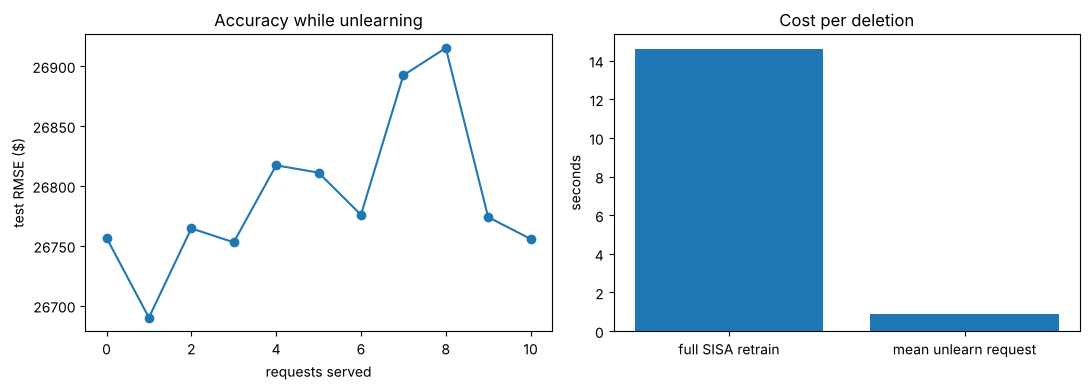

In [5]:
rng = np.random.default_rng(0)
requests = rng.choice(data.train.ids[data.train.ids != record], size=10, replace=False)
seconds, rmse = [], [test_metrics(ens)["rmse"]]
for rid in requests:
    rep = ens.unlearn([int(rid)])
    seconds.append(rep.seconds)
    rmse.append(test_metrics(ens)["rmse"])

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))
a.plot(rmse, marker="o"); a.set(xlabel="requests served", ylabel="test RMSE ($)", title="Accuracy while unlearning")
b.bar(["full SISA retrain", "mean unlearn request"], [train_seconds, np.mean(seconds)])
b.set(ylabel="seconds", title="Cost per deletion")
plt.tight_layout()
print(f"mean {np.mean(seconds):.2f}s per request vs {train_seconds:.1f}s to retrain everything "
      f"({train_seconds / np.mean(seconds):.1f}x)")